Assignment 2

Question 1

In [1]:
# Data Generation
import numpy as np
from pathlib import Path

priors=np.array([0.6, 0.4])
means=np.array([
    [[-0.9, -1.1], [0.8, 0.75]],
    [[-1.1, 0.9], [0.9, -0.75]]
])
cov=np.array([[0.75, 0.0],
              [0.0, 1.25]
              ])

def generate_q1_dataset(n, rng):
    y=rng.choice(2, size=n, p=priors)
    components=rng.integers(0, 2, size=n)

    X=np.empty((n,2))
    for L in range(2):
        for comp in range(2):
            mask=(y==L)&(components==comp)
            if np.any(mask):
                X[mask]=rng.multivariate_normal(means[L, comp], cov, size=mask.sum())
    return X, y

seeds=np.random.SeedSequence(5644).spawn(4)

X_train_20, y_train_20=generate_q1_dataset(20, np.random.default_rng(seeds[0]))
X_train_200, y_train_200=generate_q1_dataset(200, np.random.default_rng(seeds[1]))
X_train_2000, y_train_2000=generate_q1_dataset(2000, np.random.default_rng(seeds[2]))
X_validate, y_validate=generate_q1_dataset(10000, np.random.default_rng(seeds[3]))

Path("data").mkdir(exist_ok=True)

np.savez(
    "data/q1_datasets.npz",
    X_train_20=X_train_20, y_train_20=y_train_20,
    X_train_200=X_train_200, y_train_200=y_train_200,
    X_train_2000=X_train_2000, y_train_2000=y_train_2000,
    X_validate=X_validate, y_validate=y_validate
)

for name, X, y in [
    ("Train 20", X_train_20, y_train_20),
    ("Train 200", X_train_200, y_train_200),
    ("Train 2000", X_train_2000, y_train_2000),
    ("Validation 10000", X_validate, y_validate)
]:
    print(name, X.shape, np.bincount(y, minlength=2))

Train 20 (20, 2) [16  4]
Train 200 (200, 2) [117  83]
Train 2000 (2000, 2) [1201  799]
Validation 10000 (10000, 2) [6083 3917]


Incorrect samples: 2793
Validation error: 0.279300
FPR: 0.157488
TPR: 0.531529
AUC: 0.784130


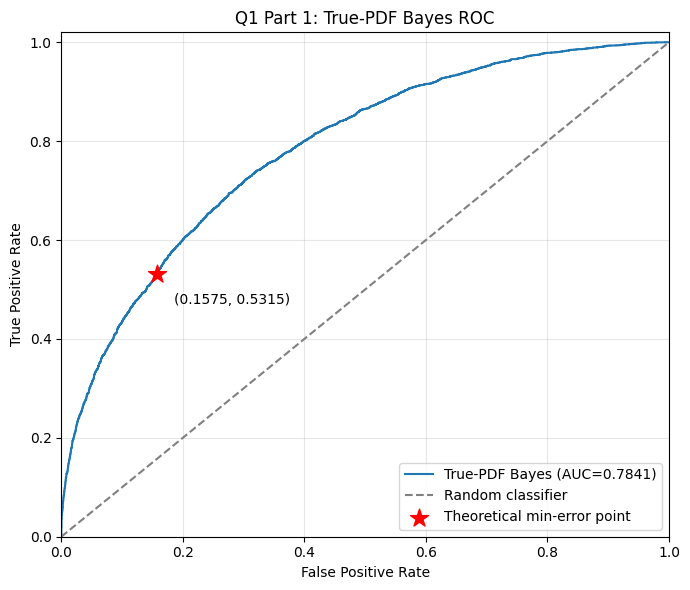

In [4]:
# Q1 Part 1
from scipy.stats import multivariate_normal
from scipy.special import logsumexp
from sklearn.metrics import roc_curve, roc_auc_score
import matplotlib.pyplot as plt

def log_joint_pdf_q1(X, cls):
    log_components = np.column_stack([
        np.log(0.5) + multivariate_normal.logpdf(X, mean=means[cls, j], cov=cov)
        for j in range(2)
    ])

    return np.log(priors[cls]) + logsumexp(log_components, axis=1)

log_score_0=log_joint_pdf_q1(X_validate, 0)
log_score_1=log_joint_pdf_q1(X_validate, 1)

scores_true=log_score_1-log_score_0
y_pred_true=(scores_true>0).astype(int)

n_errors=np.count_nonzero(y_pred_true!=y_validate)
error_true=n_errors/len(y_validate)

fpr, tpr, thresholds=roc_curve(y_validate, scores_true)
auc_true=roc_auc_score(y_validate, scores_true)

fpr_star=np.mean(y_pred_true[y_validate == 0] == 1)
tpr_star=np.mean(y_pred_true[y_validate == 1] == 1)

print(f"Incorrect samples: {n_errors}")
print(f"Validation error: {error_true:.6f}")
print(f"FPR: {fpr_star:.6f}")
print(f"TPR: {tpr_star:.6f}")
print(f"AUC: {auc_true:.6f}")

plt.figure(figsize=(7, 6))

plt.plot(fpr, tpr, label=f"True-PDF Bayes (AUC={auc_true:.4f})")
plt.plot([0, 1], [0, 1], "--", color="gray", label="Random classifier")

plt.scatter(
    fpr_star, tpr_star,
    color="red", marker="*", s=180, zorder=5,
    label="Theoretical min-error point"
)

plt.annotate(
    f"({fpr_star:.4f}, {tpr_star:.4f})",
    (fpr_star, tpr_star),
    xytext=(12, -22),
    textcoords="offset points"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Q1 Part 1: True-PDF Bayes ROC")
plt.xlim(0, 1)
plt.ylim(0, 1.02)
plt.grid(alpha=0.3)
plt.legend(loc="lower right")
plt.tight_layout()

Path("figures").mkdir(exist_ok=True)
plt.savefig("figures/q1_true_pdf_roc.pdf", bbox_inches="tight")
plt.show()

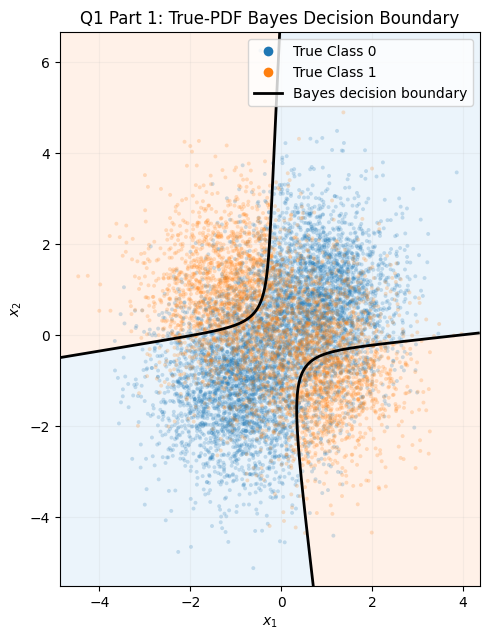

In [22]:
# Draw a decision boundary of this classifier
from matplotlib.lines import Line2D

padding = 0.4

x_min=X_validate[:, 0].min() - padding
x_max=X_validate[:, 0].max() + padding
y_min=X_validate[:, 1].min() - padding
y_max=X_validate[:, 1].max() + padding

xx, yy=np.meshgrid(
    np.linspace(x_min, x_max, 350),
    np.linspace(y_min, y_max, 350)
)

grid_points=np.column_stack([xx.ravel(), yy.ravel()])

grid_scores=(
    log_joint_pdf_q1(grid_points, 1)
    - log_joint_pdf_q1(grid_points, 0)
).reshape(xx.shape)

grid_decisions=(grid_scores > 0).astype(int)

fig, ax=plt.subplots(figsize=(8, 6.5))

ax.contourf(
    xx, yy, grid_decisions,
    levels=[-0.5, 0.5, 1.5],
    colors=["#E9F3FB", "#FFF0E6"],
    alpha=0.9
)

for cls, color in [(0, "tab:blue"), (1, "tab:orange")]:
    mask=(y_validate == cls)
    ax.scatter(
        X_validate[mask, 0],
        X_validate[mask, 1],
        s=8,
        c=color,
        alpha=0.22,
        edgecolors="none"
    )

ax.contour(
    xx, yy, grid_scores,
    levels=[0],
    colors="black",
    linewidths=2
)

legend_handles=[
    Line2D([0], [0], marker="o", linestyle="None",
           markerfacecolor="tab:blue", markeredgecolor="none",
           markersize=7, label="True Class 0"),
    Line2D([0], [0], marker="o", linestyle="None",
           markerfacecolor="tab:orange", markeredgecolor="none",
           markersize=7, label="True Class 1"),
    Line2D([0], [0], color="black", linewidth=2,
           label="Bayes decision boundary")
]

ax.legend(handles=legend_handles, loc="upper right")
ax.set_xlabel(r"$x_1$")
ax.set_ylabel(r"$x_2$")
ax.set_title("Q1 Part 1: True-PDF Bayes Decision Boundary")
ax.set_aspect("equal", adjustable="box")
ax.grid(alpha=0.12)

plt.tight_layout()
Path("figures").mkdir(exist_ok=True)
plt.savefig("figures/q1_true_pdf_boundary.png", dpi=250, bbox_inches="tight")
plt.show()

In [6]:
# Question 1 Part 2(a): Train 3 logistic-linear models

from scipy.optimize import minimize
from scipy.special import expit

def phi_linear(X):
    return np.column_stack([np.ones(X.shape[0]), X])

def linear_nll(w, Z, y):
    logits=Z @ w
    return np.mean(np.logaddexp(0, logits) - y * logits)

def linear_gradient(w, Z, y):
    h=expit(Z @ w)
    return Z.T @ (h - y) / len(y)

train_sets={20: (X_train_20, y_train_20), 200: (X_train_200, y_train_200), 2000: (X_train_2000, y_train_2000)}

linear_results={}

for n, (X_train, y_train) in train_sets.items():
    Z_train=phi_linear(X_train)

    result = minimize(
        linear_nll,
        x0=np.zeros(3),
        args=(Z_train, y_train),
        jac=linear_gradient,
        method="BFGS",
        options={"gtol": 1e-9, "maxiter": 2000}
    )

    w_hat = result.x

    train_pred=(Z_train @ w_hat > 0).astype(int)
    validate_pred=(phi_linear(X_validate) @ w_hat > 0).astype(int)

    train_error=np.mean(train_pred != y_train)
    validate_error=np.mean(validate_pred != y_validate)

    linear_results[n]={
        "w": w_hat,
        "nll": result.fun,
        "train_error": train_error,
        "validate_error": validate_error,
        "success": result.success
    }

    print(f"Training samples: {n}")
    print("Converged:", result.success)
    print("Estimated w:", np.round(w_hat, 6))
    print(f"Training NLL: {result.fun:.6f}")
    print(f"Training error: {train_error:.6f}")
    print(f"Validation error: {validate_error:.6f}")
    print("-" * 45)


Training samples: 20
Converged: True
Estimated w: [-1.153617  0.233508  0.271222]
Training NLL: 0.491004
Training error: 0.200000
Validation error: 0.396900
---------------------------------------------
Training samples: 200
Converged: True
Estimated w: [-0.316796 -0.042704  0.278176]
Training NLL: 0.660156
Training error: 0.345000
Validation error: 0.397600
---------------------------------------------
Training samples: 2000
Converged: True
Estimated w: [-0.409824 -0.066694  0.14027 ]
Training NLL: 0.667689
Training error: 0.383000
Validation error: 0.378100
---------------------------------------------


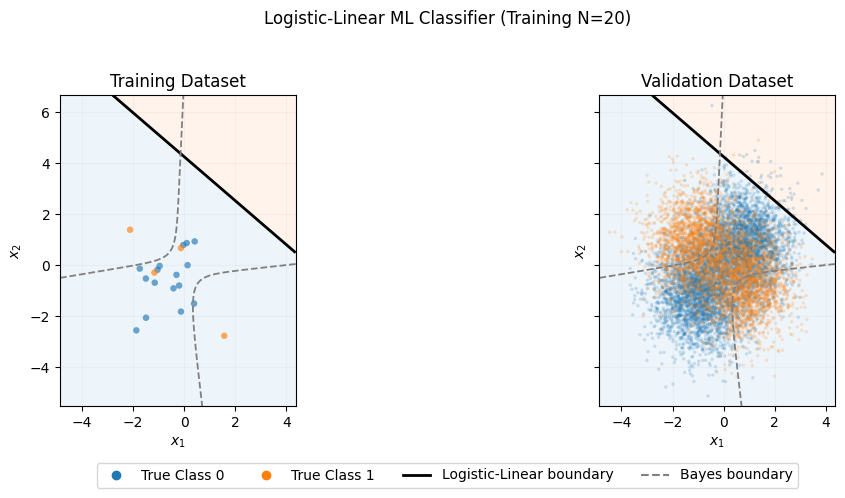

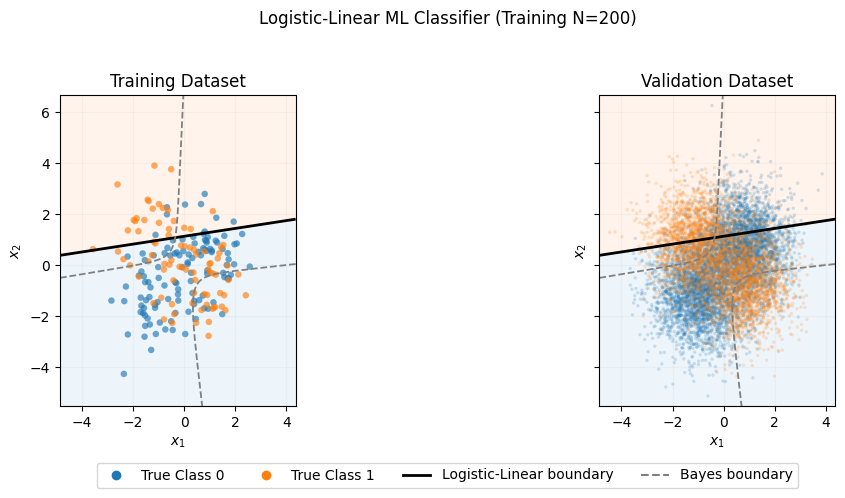

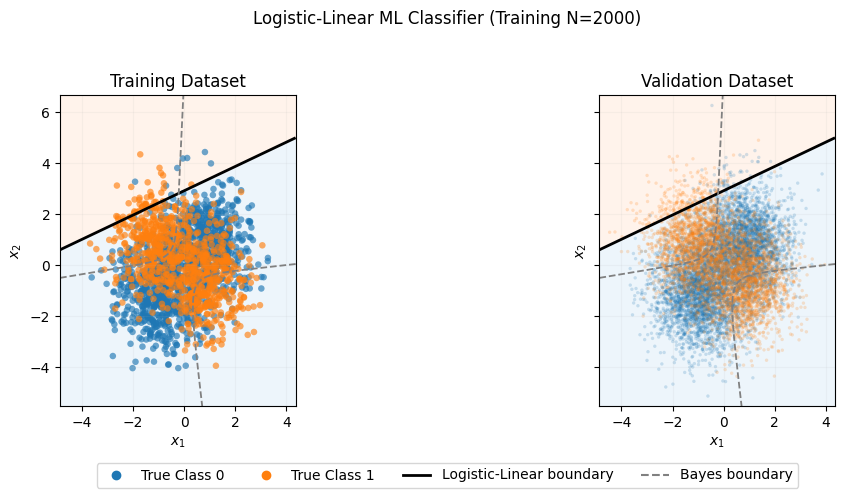

In [7]:
# Decision Boundary of linear-logistic models

from matplotlib.lines import Line2D

padding=0.4

x_min=X_validate[:, 0].min() - padding
x_max=X_validate[:, 0].max() + padding
y_min=X_validate[:, 1].min() - padding
y_max=X_validate[:, 1].max() + padding

xx, yy=np.meshgrid(np.linspace(x_min, x_max, 320), np.linspace(y_min, y_max, 320))

grid_points = np.column_stack([xx.ravel(), yy.ravel()])

bayes_scores_grid=(log_joint_pdf_q1(grid_points, 1) - log_joint_pdf_q1(grid_points, 0)).reshape(xx.shape)

legend_handles=[
    Line2D([0], [0], marker="o", linestyle="None", color="tab:blue", label="True Class 0"),
    Line2D([0], [0], marker="o", linestyle="None", color="tab:orange", label="True Class 1"),
    Line2D([0], [0], color="black", linewidth=2, label="Logistic-Linear boundary"),
    Line2D([0], [0], color="gray", linestyle="--", label="Bayes boundary")
]

Path("figures").mkdir(exist_ok=True)

for n, (X_train, y_train) in train_sets.items():
    w_hat=linear_results[n]["w"]
    grid_scores=(phi_linear(grid_points) @ w_hat).reshape(xx.shape)

    fig, axes=plt.subplots(1, 2, figsize=(12, 5), sharex=True, sharey=True)

    for ax, X, y, title in zip(
        axes,
        [X_train, X_validate],
        [y_train, y_validate],
        ["Training Dataset", "Validation Dataset"]
    ):
        ax.contourf(
            xx, yy, (grid_scores > 0).astype(int),
            levels=[-0.5, 0.5, 1.5],
            colors=["#E9F3FB", "#FFF0E6"],
            alpha=0.8
        )

        for cls, color in [(0, "tab:blue"), (1, "tab:orange")]:
            mask=(y == cls)
            ax.scatter(
                X[mask, 0], X[mask, 1],
                s=22 if title == "Training Dataset" else 6,
                c=color,
                alpha=0.65 if title == "Training Dataset" else 0.20,
                edgecolors="none"
            )

        ax.contour(xx, yy, grid_scores, levels=[0], colors="black", linewidths=2)
        ax.contour(xx, yy, bayes_scores_grid, levels=[0], colors="gray", linestyles="--", linewidths=1.3)

        ax.set_title(title)
        ax.set_xlabel(r"$x_1$")
        ax.set_ylabel(r"$x_2$")
        ax.set_aspect("equal", adjustable="box")
        ax.grid(alpha=0.1)

    fig.suptitle(f"Logistic-Linear ML Classifier (Training N={n})")
    fig.legend(handles=legend_handles, loc="lower center", ncol=4, bbox_to_anchor=(0.5, 0.01))
    fig.tight_layout(rect=[0, 0.07, 1, 0.95])

    plt.savefig(f"figures/q1_linear_boundary_{n}.pdf", bbox_inches="tight")
    plt.show()


In [8]:
# Train 3 quadratic logistic models
def phi_quadratic(X):
    x1=X[:, 0]
    x2=X[:, 1]
    return np.column_stack([np.ones(X.shape[0]), x1, x2, x1**2, x1*x2, x2**2])

quadratic_results={}

for n, (X_train, y_train) in train_sets.items():
    Z_train=phi_quadratic(X_train)

    result=minimize(linear_nll, x0=np.zeros(6), args=(Z_train, y_train), jac=linear_gradient, method="BFGS", options={"gtol": 1e-9, "maxiter": 2000})

    w_hat=result.x
    train_pred=(Z_train @ w_hat > 0).astype(int)
    validate_pred=(phi_quadratic(X_validate) @ w_hat > 0).astype(int)

    train_error=np.mean(train_pred != y_train)
    validate_error=np.mean(validate_pred != y_validate)

    quadratic_results[n]={
        "w": w_hat,
        "nll": result.fun,
        "train_error": train_error,
        "validate_error": validate_error,
        "success": result.success
    }

    print(f"Training samples: {n}")
    print("Converged:", result.success)
    print("Estimated w:", np.round(w_hat, 6))
    print(f"Training NLL: {result.fun:.6f}")
    print(f"Training error: {train_error:.6f}")
    print(f"Validation error: {validate_error:.6f}")
    print("-" * 45)

Training samples: 20
Converged: True
Estimated w: [-3.757737 -6.565673  2.090395 -2.714805 -4.507075  1.417418]
Training NLL: 0.236156
Training error: 0.100000
Validation error: 0.332300
---------------------------------------------
Training samples: 200
Converged: True
Estimated w: [-0.406987 -0.103494  0.097353  0.003568 -0.852218  0.016275]
Training NLL: 0.536612
Training error: 0.305000
Validation error: 0.277400
---------------------------------------------
Training samples: 2000
Converged: True
Estimated w: [-0.279435 -0.045845  0.101793  0.005073 -0.841475 -0.090277]
Training NLL: 0.541900
Training error: 0.286000
Validation error: 0.279600
---------------------------------------------


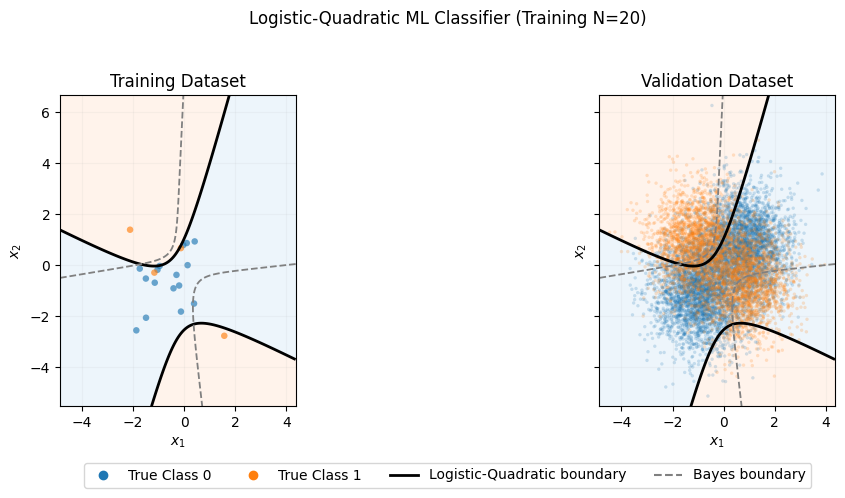

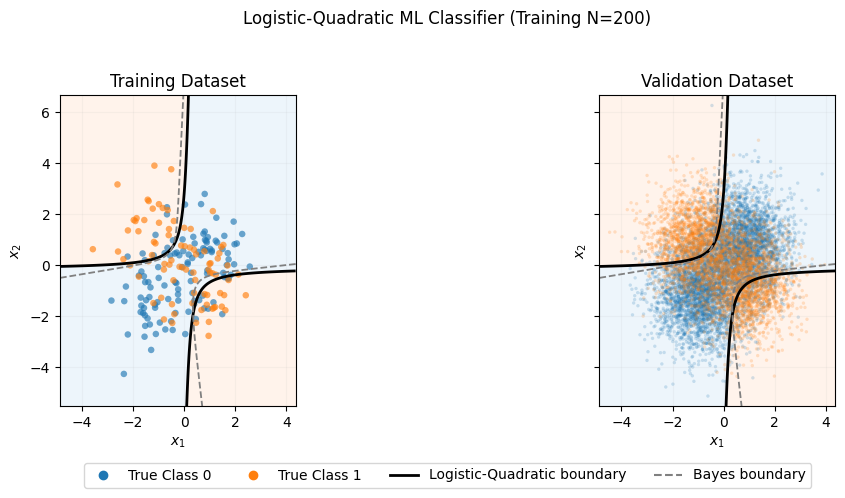

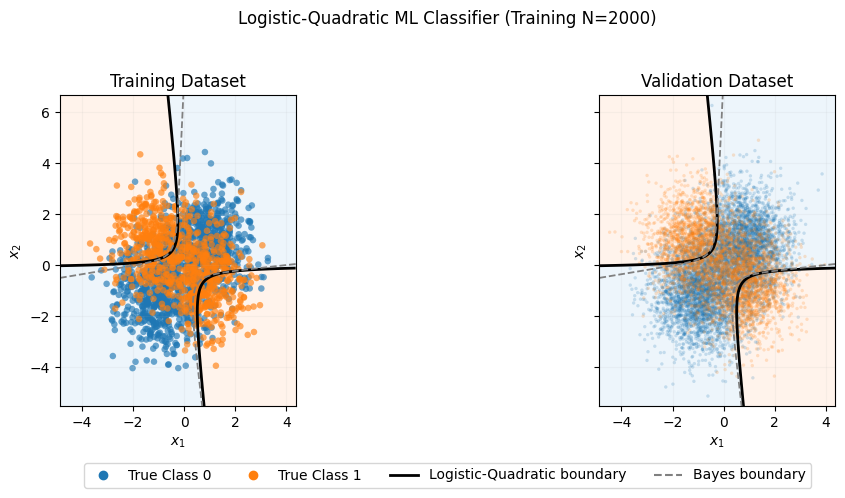

In [9]:
# Decision Boundary of quadratic-logistic models
from matplotlib.lines import Line2D

legend_handles_q=[
    Line2D([0], [0], marker="o", linestyle="None", color="tab:blue", label="True Class 0"),
    Line2D([0], [0], marker="o", linestyle="None", color="tab:orange", label="True Class 1"),
    Line2D([0], [0], color="black", linewidth=2, label="Logistic-Quadratic boundary"),
    Line2D([0], [0], color="gray", linestyle="--", label="Bayes boundary")
]

Path("figures").mkdir(exist_ok=True)

for n, (X_train, y_train) in train_sets.items():
    w_hat=quadratic_results[n]["w"]
    grid_scores=(phi_quadratic(grid_points) @ w_hat).reshape(xx.shape)

    fig, axes=plt.subplots(1, 2, figsize=(12, 5), sharex=True, sharey=True)

    for ax, X, y, title in zip(axes, [X_train, X_validate], [y_train, y_validate], ["Training Dataset", "Validation Dataset"]):
        ax.contourf(xx, yy, (grid_scores > 0).astype(int), levels=[-0.5, 0.5, 1.5], colors=["#E9F3FB", "#FFF0E6"], alpha=0.8)

        for cls, color in [(0, "tab:blue"), (1, "tab:orange")]:
            mask=(y == cls)
            ax.scatter(X[mask, 0], X[mask, 1], s=22 if title == "Training Dataset" else 6, c=color, alpha=0.65 if title == "Training Dataset" else 0.20, edgecolors="none")

        ax.contour(xx, yy, grid_scores, levels=[0], colors="black", linewidths=2)
        ax.contour(xx, yy, bayes_scores_grid, levels=[0], colors="gray", linestyles="--", linewidths=1.3)

        ax.set_title(title)
        ax.set_xlabel(r"$x_1$")
        ax.set_ylabel(r"$x_2$")
        ax.set_aspect("equal", adjustable="box")
        ax.grid(alpha=0.1)

    fig.suptitle(f"Logistic-Quadratic ML Classifier (Training N={n})")
    fig.legend(handles=legend_handles_q, loc="lower center", ncol=4, bbox_to_anchor=(0.5, 0.01))
    fig.tight_layout(rect=[0, 0.07, 1, 0.95])

    plt.savefig(f"figures/q1_quadratic_boundary_{n}.pdf", bbox_inches="tight")
    plt.show()


In [10]:
# summarize results
print(f"{'Model':<25} {'Train Error':>14} {'Validation Error':>18}")
print("-" * 60)
print(f"{'True-PDF Bayes':<25} {'N/A':>14} {error_true:>18.6f}")

for n in [20, 200, 2000]:
    r = linear_results[n]
    print(f"{'Logistic-Linear ' + str(n):<25} {r['train_error']:>14.6f} {r['validate_error']:>18.6f}")

for n in [20, 200, 2000]:
    r = quadratic_results[n]
    print(f"{'Logistic-Quadratic ' + str(n):<25} {r['train_error']:>14.6f} {r['validate_error']:>18.6f}")


Model                        Train Error   Validation Error
------------------------------------------------------------
True-PDF Bayes                       N/A           0.279300
Logistic-Linear 20              0.200000           0.396900
Logistic-Linear 200             0.345000           0.397600
Logistic-Linear 2000            0.383000           0.378100
Logistic-Quadratic 20           0.100000           0.332300
Logistic-Quadratic 200          0.305000           0.277400
Logistic-Quadratic 2000         0.286000           0.279600


Question 2

Training X: (100, 2)
Training y: (100,)
Validation X: (1000, 2)
Validation y: (1000,)


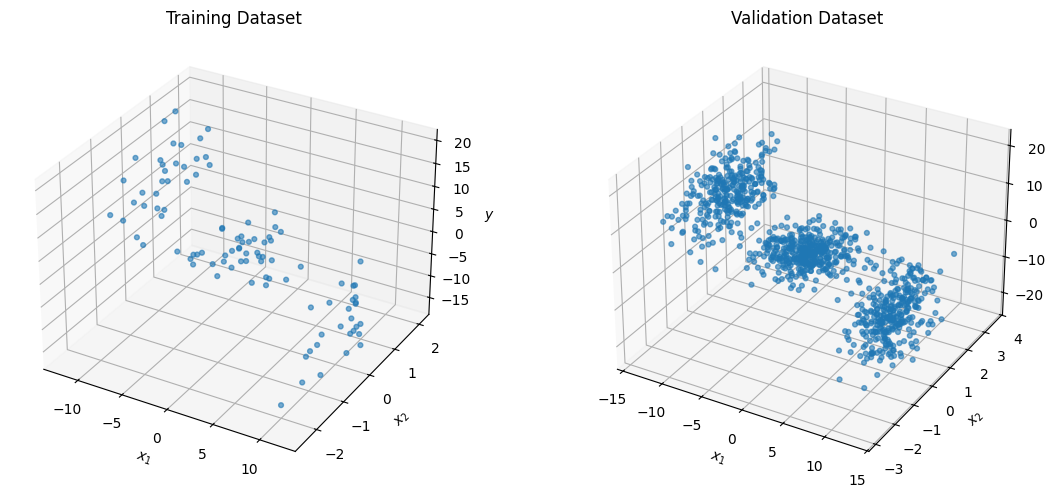

In [12]:
# Generate Dataset
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
import runpy

q2_generator=runpy.run_path("hw2q2-1.py")["generateData"]

np.random.seed(5644)

q2_train_data=q2_generator(100)
q2_validate_data=q2_generator(1000)

X2_train=q2_train_data[:2, :].T
y2_train=q2_train_data[2, :]

X2_validate=q2_validate_data[:2, :].T
y2_validate=q2_validate_data[2, :]

Path("data").mkdir(exist_ok=True)

np.savez(
    "data/q2_datasets.npz",
    X_train=X2_train,
    y_train=y2_train,
    X_validate=X2_validate,
    y_validate=y2_validate
)

print("Training X:", X2_train.shape)
print("Training y:", y2_train.shape)
print("Validation X:", X2_validate.shape)
print("Validation y:", y2_validate.shape)

fig = plt.figure(figsize=(12, 5))

for i, (X, y, title) in enumerate([
    (X2_train, y2_train, "Training Dataset"),
    (X2_validate, y2_validate, "Validation Dataset")
]):
    ax=fig.add_subplot(1, 2, i + 1, projection="3d")
    ax.scatter(X[:, 0], X[:, 1], y, s=12, alpha=0.6)
    ax.set_xlabel("$x_1$")
    ax.set_ylabel("$x_2$")
    ax.set_zlabel("$y$")
    ax.set_title(title)

plt.tight_layout()

Path("figures").mkdir(exist_ok=True)
plt.savefig("figures/q2_datasets.pdf", bbox_inches="tight")
plt.show()

In [14]:
# Implement Cubic Feature Mapping and ML Estimator
def phi_cubic(X):
    x1=X[:, 0]
    x2=X[:, 1]

    return np.column_stack([
        np.ones(X.shape[0]),
        x1, x2,
        x1**2, x1*x2, x2**2,
        x1**3, x1**2*x2, x1*x2**2, x2**3
    ])

Phi2_train=phi_cubic(X2_train)
Phi2_validate=phi_cubic(X2_validate)

# ML estimator using least squares
w2_ml=np.linalg.lstsq(Phi2_train, y2_train, rcond=None)[0]

# Predictions
y2_train_pred=Phi2_train @ w2_ml
y2_validate_pred=Phi2_validate @ w2_ml

# Mean squared errors
mse2_train_ml=np.mean((y2_train - y2_train_pred)**2)
mse2_validate_ml=np.mean((y2_validate - y2_validate_pred)**2)

# Plug-in estimate of Gaussian noise variance
sigma2_hat=mse2_train_ml

print("Design matrix shape:", Phi2_train.shape)
print("Estimated ML parameters:", np.round(w2_ml, 6))
print(f"Training MSE: {mse2_train_ml:.6f}")
print(f"Validation MSE: {mse2_validate_ml:.6f}")
print(f"Estimated sigma^2: {sigma2_hat:.6f}")

Design matrix shape: (100, 10)
Estimated ML parameters: [ 0.128328  0.171853  0.166871 -0.00243  -0.020491  0.073329 -0.010819
  0.01101  -0.024736 -0.470304]
Training MSE: 3.272349
Validation MSE: 5.454708
Estimated sigma^2: 3.272349


In [16]:
# Implement ML Estimator and sweep Gamma
gamma_values=np.logspace(-10, 5, 151)

PhiTPhi=Phi2_train.T @ Phi2_train
PhiTy=Phi2_train.T @ y2_train
I=np.eye(Phi2_train.shape[1])

map_weights=[]
map_train_mse=[]
map_validate_mse=[]

for gamma in gamma_values:
    lam = sigma2_hat / gamma

    w_map = np.linalg.solve(PhiTPhi + lam * I, PhiTy)
    train_pred = Phi2_train @ w_map
    validate_pred = Phi2_validate @ w_map

    train_mse=np.mean((y2_train - train_pred)**2)
    validate_mse=np.mean((y2_validate - validate_pred)**2)

    map_weights.append(w_map)
    map_train_mse.append(train_mse)
    map_validate_mse.append(validate_mse)

map_weights=np.array(map_weights)
map_train_mse=np.array(map_train_mse)
map_validate_mse=np.array(map_validate_mse)

best_idx=np.argmin(map_validate_mse)
best_gamma=gamma_values[best_idx]
best_w_map=map_weights[best_idx]
best_map_mse=map_validate_mse[best_idx]

print(f"ML Validation MSE: {mse2_validate_ml:.6f}")
print(f"Best Gamma: {best_gamma:.8e}")
print(f"Best MAP Validation MSE: {best_map_mse:.6f}")
print(f"Best MAP Training MSE: {map_train_mse[best_idx]:.6f}")
print("Best MAP parameters:", np.round(best_w_map, 6))

print(f"\nSmallest Gamma MSE: {map_validate_mse[0]:.6f}")
print(f"Largest Gamma MSE: {map_validate_mse[-1]:.6f}")

ML Validation MSE: 5.454708
Best Gamma: 6.30957344e-06
Best MAP Validation MSE: 4.426755
Best MAP Training MSE: 3.623852
Best MAP parameters: [ 4.000e-06  3.000e-05  1.700e-05  7.480e-04 -3.420e-04  2.300e-05
 -9.271e-03  2.300e-03  1.410e-04 -4.700e-05]

Smallest Gamma MSE: 72.044068
Largest Gamma MSE: 5.454706


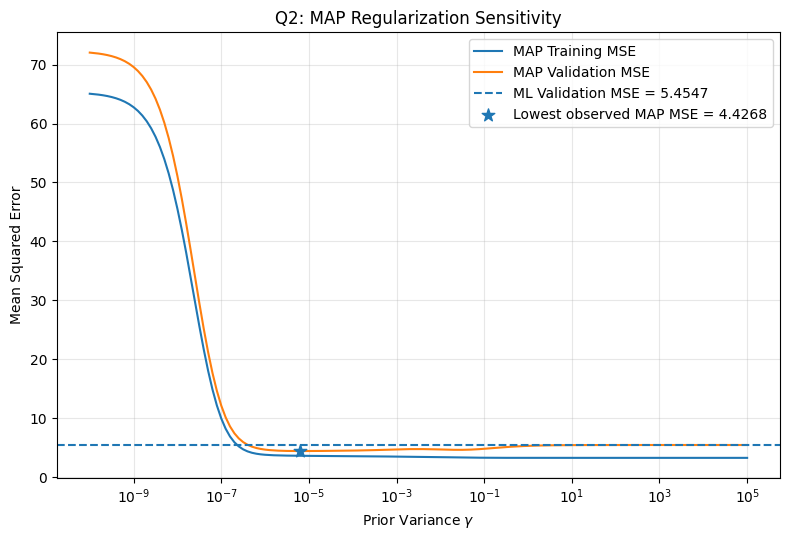

In [17]:
# Draw Validation MSE vs. Gamma
plt.figure(figsize=(8, 5.5))

plt.semilogx(gamma_values, map_train_mse, label="MAP Training MSE")
plt.semilogx(gamma_values, map_validate_mse, label="MAP Validation MSE")

plt.axhline(
    mse2_validate_ml,
    linestyle="--",
    label=f"ML Validation MSE = {mse2_validate_ml:.4f}"
)

plt.scatter(
    best_gamma, best_map_mse,
    s=90, marker="*",
    zorder=5,
    label=f"Lowest observed MAP MSE = {best_map_mse:.4f}"
)

plt.xlabel(r"Prior Variance $\gamma$")
plt.ylabel("Mean Squared Error")
plt.title("Q2: MAP Regularization Sensitivity")
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()

Path("figures").mkdir(exist_ok=True)
plt.savefig("figures/q2_map_mse_vs_gamma.pdf", bbox_inches="tight")
plt.show()

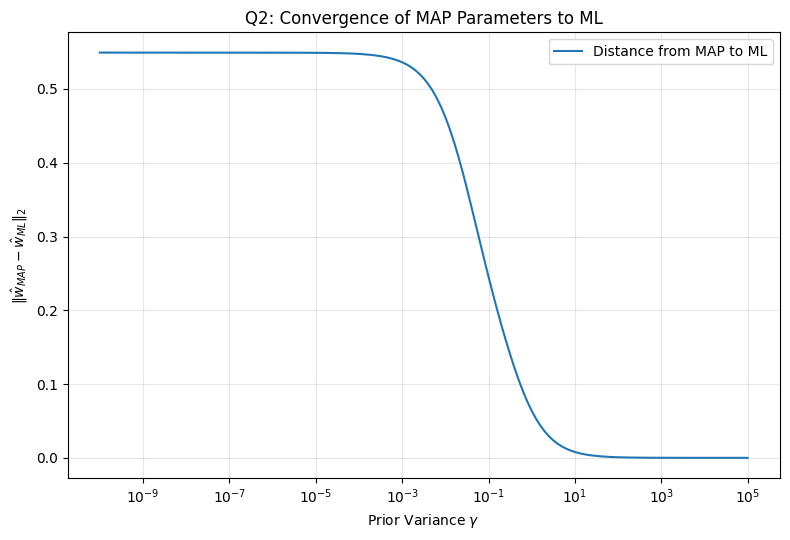

ML parameter norm: 0.5492600291933208
MAP norm at smallest gamma: 2.0017698982758347e-05
MAP norm at largest gamma: 0.5492594709903384
Distance to ML at largest gamma: 8.18935595434249e-07


In [18]:
# Validate MAP estimate to ML estimate

distance_to_ml=np.linalg.norm(map_weights - w2_ml, axis=1)
weight_norms=np.linalg.norm(map_weights, axis=1)

plt.figure(figsize=(8, 5.5))
plt.semilogx(gamma_values, distance_to_ml, label="Distance from MAP to ML")
plt.xlabel(r"Prior Variance $\gamma$")
plt.ylabel(r"$\|\hat{w}_{MAP}-\hat{w}_{ML}\|_2$")
plt.title("Q2: Convergence of MAP Parameters to ML")
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()

plt.savefig("figures/q2_map_ml_distance.pdf", bbox_inches="tight")
plt.show()

print("ML parameter norm:", np.linalg.norm(w2_ml))
print("MAP norm at smallest gamma:", weight_norms[0])
print("MAP norm at largest gamma:", weight_norms[-1])
print("Distance to ML at largest gamma:", distance_to_ml[-1])

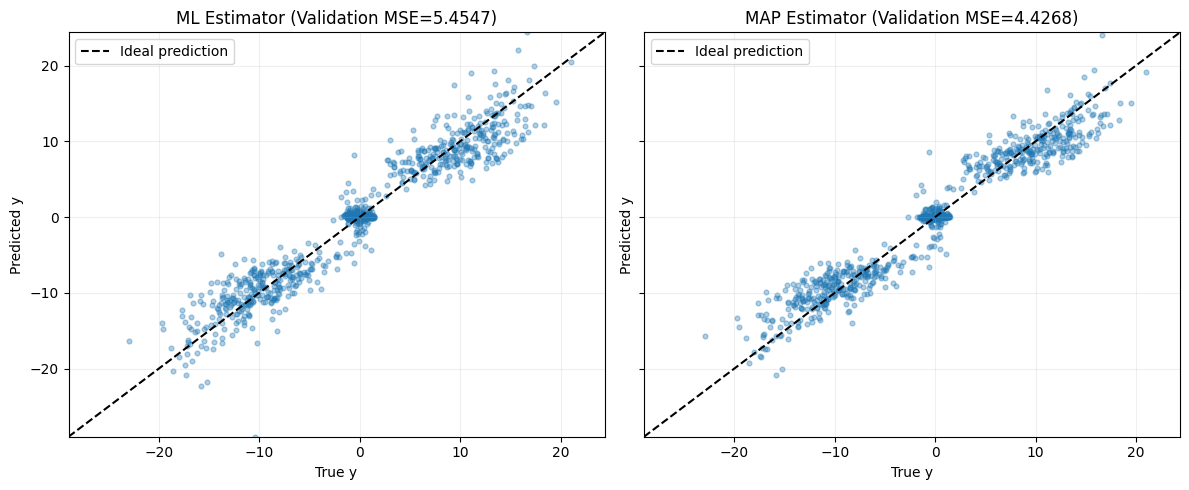

In [19]:
# Comparison of predictions between ML and MAP

# Compare ML and best MAP predictions on validation samples
y_pred_ml=Phi2_validate @ w2_ml
y_pred_map=Phi2_validate @ best_w_map

lower=min(y2_validate.min(), y_pred_ml.min(), y_pred_map.min())
upper=max(y2_validate.max(), y_pred_ml.max(), y_pred_map.max())

fig, axes=plt.subplots(1, 2, figsize=(12, 5), sharex=True, sharey=True)

for ax, pred, title, mse in [
    (axes[0], y_pred_ml, "ML Estimator", mse2_validate_ml),
    (axes[1], y_pred_map, "MAP Estimator", best_map_mse)
]:
    ax.scatter(y2_validate, pred, s=12, alpha=0.35)
    ax.plot([lower, upper], [lower, upper], "k--", linewidth=1.5, label="Ideal prediction")
    ax.set_title(f"{title} (Validation MSE={mse:.4f})")
    ax.set_xlabel("True y")
    ax.set_ylabel("Predicted y")
    ax.set_xlim(lower, upper)
    ax.set_ylim(lower, upper)
    ax.grid(alpha=0.2)
    ax.legend()

plt.tight_layout()
plt.savefig("figures/q2_ml_map_prediction_comparison.pdf", bbox_inches="tight")
plt.show()

Question 3

In [20]:
# Generate distance measurements and calculate the MAP Estimate
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import minimize
from pathlib import Path

rng_q3=np.random.default_rng(5644)

q3_true_pos=np.array([0.50, -0.35])
q3_sigma_r=0.30
q3_prior_sigma=np.array([0.25, 0.25])

assert np.linalg.norm(q3_true_pos) < 1.0

def q3_map_objective(pos, landmarks, ranges):
    distances=np.linalg.norm(pos - landmarks, axis=1)
    measurement_term=np.sum(((ranges - distances) / q3_sigma_r)**2)
    prior_term=np.sum((pos / q3_prior_sigma)**2)
    return measurement_term + prior_term

q3_cases={}

initial_guesses=np.array([
    [0.0, 0.0],
    [0.5, 0.0],
    [-0.5, 0.0],
    [0.0, 0.5],
    [0.0, -0.5],
    [0.5, 0.5],
    [-0.5, -0.5]
])

for K in [1, 2, 3, 4]:
    angles=2 * np.pi * np.arange(K) / K
    landmarks=np.column_stack([np.cos(angles), np.sin(angles)])
    true_ranges=np.linalg.norm(q3_true_pos - landmarks, axis=1)

    ranges=np.empty(K)
    for i in range(K):
        r=true_ranges[i] + rng_q3.normal(0, q3_sigma_r)
        while r < 0:
            r=true_ranges[i] + rng_q3.normal(0, q3_sigma_r)
        ranges[i]=r

    solutions=[
        minimize(q3_map_objective, x0, args=(landmarks, ranges), method="BFGS")
        for x0 in initial_guesses
    ]

    best=min(solutions, key=lambda result: result.fun)
    position_error=np.linalg.norm(best.x - q3_true_pos)

    q3_cases[K]={
        "landmarks": landmarks,
        "ranges": ranges,
        "estimate": best.x,
        "min_objective": best.fun,
        "position_error": position_error
    }

    print(f"K = {K}")
    print("Measured ranges:", np.round(ranges, 4))
    print("MAP estimate:", np.round(best.x, 4))
    print(f"Position error: {position_error:.6f}")
    print(f"Minimum objective: {best.fun:.6f}")
    print("-" * 45)

K = 1
Measured ranges: [0.3618]
MAP estimate: [ 0.2616 -0.    ]
Position error: 0.423506
Minimum objective: 2.670721
---------------------------------------------
K = 2
Measured ranges: [0.3084 0.8282]
MAP estimate: [ 0.1511 -0.    ]
Position error: 0.494189
Minimum objective: 4.769435
---------------------------------------------
K = 3
Measured ranges: [0.4451 1.9519 1.0494]
MAP estimate: [ 0.37   -0.2452]
Position error: 0.166973
Minimum objective: 6.996995
---------------------------------------------
K = 4
Measured ranges: [0.2663 1.2191 1.8335 1.384 ]
MAP estimate: [0.5029 0.0458]
Position error: 0.395781
Minimum objective: 6.666523
---------------------------------------------


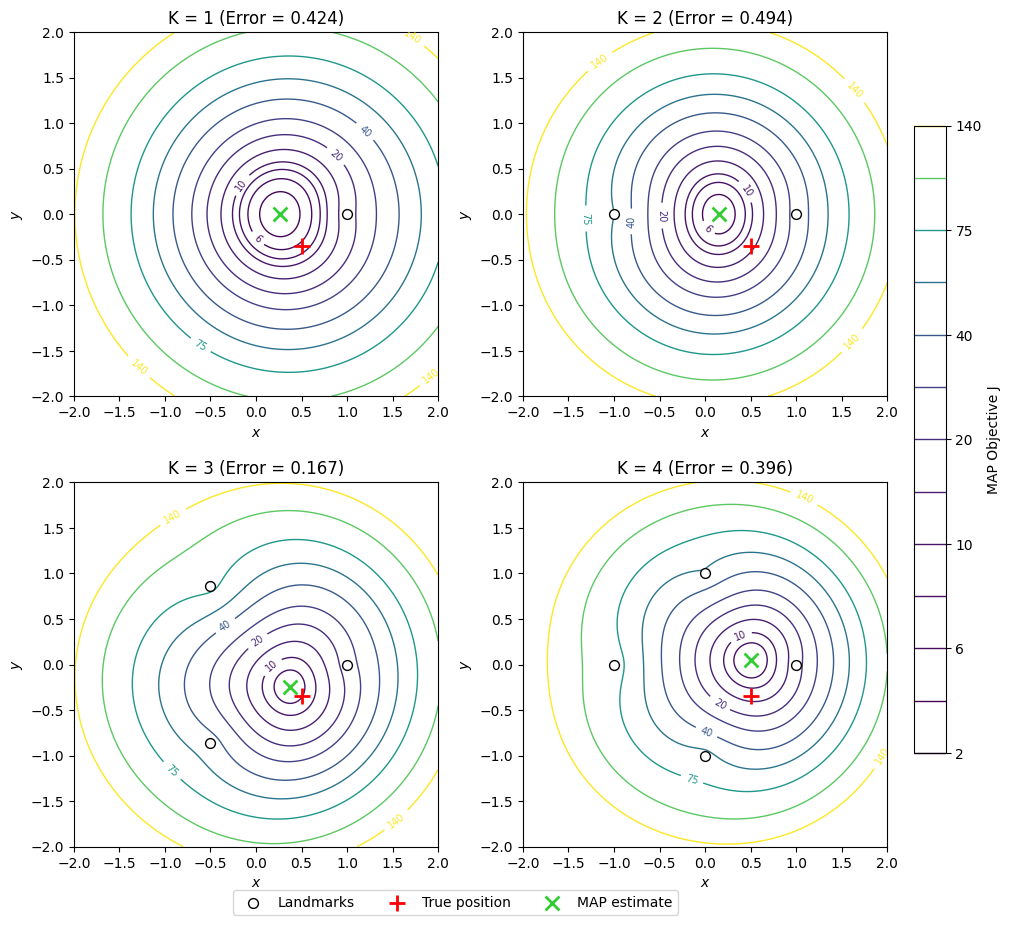

In [21]:
# Draw four MAP Objective Contour Plots
q3_grid=np.linspace(-2, 2, 251)
q3_xx, q3_yy = np.meshgrid(q3_grid, q3_grid)

q3_levels=np.array([2, 4, 6, 8, 10, 14, 20, 28, 40, 55, 75, 105, 140])

def q3_draw_contours(ax, case, K):
    landmarks=case["landmarks"]
    ranges=case["ranges"]

    distances=np.sqrt(
        (q3_xx[..., None] - landmarks[:, 0])**2
        + (q3_yy[..., None] - landmarks[:, 1])**2
    )

    J_grid=np.sum(((ranges[None, None, :] - distances) / q3_sigma_r)**2, axis=2)
    J_grid+=(q3_xx / q3_prior_sigma[0])**2 + (q3_yy / q3_prior_sigma[1])**2

    cs=ax.contour(q3_xx, q3_yy, J_grid, levels=q3_levels, cmap="viridis", linewidths=1.0)
    ax.clabel(cs, levels=q3_levels[::2], inline=True, fontsize=7)

    ax.scatter(landmarks[:, 0], landmarks[:, 1], s=50, marker="o", facecolors="white", edgecolors="black", label="Landmarks", zorder=5)
    ax.scatter(*q3_true_pos, s=120, marker="+", color="red", linewidths=2, label="True position", zorder=6)
    ax.scatter(*case["estimate"], s=100, marker="x", color="limegreen", linewidths=2, label="MAP estimate", zorder=6)

    ax.set_xlim(-2, 2)
    ax.set_ylim(-2, 2)
    ax.set_aspect("equal")
    ax.set_xlabel("$x$")
    ax.set_ylabel("$y$")
    ax.set_title(f"K = {K} (Error = {case['position_error']:.3f})")

    return cs

Path("figures").mkdir(exist_ok=True)

# Combined 2x2 figure
fig, axes=plt.subplots(2, 2, figsize=(10, 9), layout="constrained")

for K, ax in zip([1, 2, 3, 4], axes.ravel()):
    cs=q3_draw_contours(ax, q3_cases[K], K)

handles, labels=axes[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center", ncol=3, bbox_to_anchor=(0.45, -0.025))
fig.colorbar(cs, ax=axes.ravel().tolist(), shrink=0.72, label="MAP Objective J", pad=0.02)

plt.savefig("figures/q3_map_contours.pdf", bbox_inches="tight")
plt.show()

# Save four separate figures for Overleaf if needed
for K in [1, 2, 3, 4]:
    fig_single, ax_single=plt.subplots(figsize=(5.5, 5))
    q3_draw_contours(ax_single, q3_cases[K], K)
    ax_single.legend(loc="upper right", fontsize=8)
    fig_single.tight_layout()
    fig_single.savefig(f"figures/q3_contours_K{K}.pdf", bbox_inches="tight")
    plt.close(fig_single)

In [23]:
# Certainty Analysis
from scipy.special import logsumexp

grid_points=np.column_stack([q3_xx.ravel(), q3_yy.ravel()])
grid_cell_area=float((q3_grid[1] - q3_grid[0])**2)

q3_uncertainty_results={}

for K in [1, 2, 3, 4]:
    landmarks=q3_cases[K]["landmarks"]
    ranges=q3_cases[K]["ranges"]

    distances=np.sqrt((q3_xx[..., None] - landmarks[:, 0])**2 + (q3_yy[..., None] - landmarks[:, 1])**2)
    J_grid=np.sum(((ranges[None, None, :] - distances) / q3_sigma_r)**2, axis=2)
    J_grid+=(q3_xx / q3_prior_sigma[0])**2 + (q3_yy / q3_prior_sigma[1])**2

    log_posterior=-0.5 * J_grid.ravel()
    probabilities=np.exp(log_posterior - logsumexp(log_posterior))

    posterior_mean=probabilities @ grid_points
    centered=grid_points - posterior_mean
    posterior_cov=(centered * probabilities[:, None]).T @ centered

    sorted_probabilities=np.sort(probabilities)[::-1]
    num_hpd_cells=np.searchsorted(np.cumsum(sorted_probabilities), 0.90) + 1
    hpd_area=num_hpd_cells * grid_cell_area

    q3_uncertainty_results[K]={
        "posterior_mean": posterior_mean,
        "posterior_cov": posterior_cov,
        "cov_trace": np.trace(posterior_cov),
        "hpd_90_area": hpd_area
    }

    print(f"K={K}: Position Error={q3_cases[K]['position_error']:.4f}, Cov Trace={np.trace(posterior_cov):.5f}, 90% HPD Area={hpd_area:.4f}")


K=1: Position Error=0.4235, Cov Trace=0.08344, 90% HPD Area=0.6003
K=2: Position Error=0.4942, Cov Trace=0.06420, 90% HPD Area=0.4572
K=3: Position Error=0.1670, Cov Trace=0.06277, 90% HPD Area=0.4524
K=4: Position Error=0.3958, Cov Trace=0.05379, 90% HPD Area=0.3886
